In [1]:
import os
# --- threshold_test parameters (set by run_all.py through the environment) ---
THRESH_TAG = os.environ.get('THRESH_TAG', 'm2.4')   # m2.4 = baseline cut of -2.4 dex
DATA_DIR = os.path.join('..', '..', 'data', f'thresh_{THRESH_TAG}')
OUT_ROOT = os.path.join('..', '..', 'outputs', f'thresh_{THRESH_TAG}')


In [2]:
import pandas as pd

In [3]:
low_mass_satellite_df = pd.read_parquet(os.path.join(DATA_DIR, 'low_mass_satellite_df_annuli_revised.parquet'))

In [4]:
low_mass_satellite_df

,subID,bin_radii,avg_s_mass,avg_SFR,avg_gas_mass,quenching_vector,gas_mass,s_mass,BHMass,class,veldisp,global_SFRs,BH_cumQM,BH_cumRM,Mhalo,overdens,bulge,Bfld,BH_AGN,GrNr
439,37.0,0.174505,8.905776,-0.052619,8.682093,0,0.022175,1.336990,0.003621,1,77.483803,2.468716,8761.889648,0.000000e+00,38878.035156,202.795135,-0.682291,0.694089,8.761890e+03,0
440,37.0,0.523516,8.636583,-0.643683,8.302815,0,0.022175,1.336990,0.003621,1,77.483803,2.468716,8761.889648,0.000000e+00,38878.035156,202.795135,-0.682291,0.694089,8.761890e+03,0
441,37.0,0.872526,8.421218,-1.414926,7.867777,0,0.022175,1.336990,0.003621,1,77.483803,2.468716,8761.889648,0.000000e+00,38878.035156,202.795135,-0.682291,0.694089,8.761890e+03,0
442,37.0,1.221537,8.243556,-1.699316,7.714798,0,0.022175,1.336990,0.003621,1,77.483803,2.468716,8761.889648,0.000000e+00,38878.035156,202.795135,-0.682291,0.694089,8.761890e+03,0
443,37.0,1.570547,8.094305,-1.657207,7.711024,0,0.022175,1.336990,0.003621,1,77.483803,2.468716,8761.889648,0.000000e+00,38878.035156,202.795135,-0.682291,0.694089,8.761890e+03,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54860,593573.0,0.461125,7.915781,-3.874264,7.566107,1,0.000000,0.146896,0.000124,1,44.716286,0.059573,0.000000,1.027657e-321,21.333946,3.807714,-0.044053,0.168837,1.027657e-321,5991
54861,593573.0,0.768541,7.496673,-2.880743,7.366165,0,0.000000,0.146896,0.000124,1,44.716286,0.059573,0.000000,1.027657e-321,21.333946,3.807714,-0.044053,0.168837,1.027657e-321,5991
54862,593573.0,1.075957,7.168706,-3.435107,7.380437,0,0.000000,0.146896,0.000124,1,44.716286,0.059573,0.000000,1.027657e-321,21.333946,3.807714,-0.044053,0.168837,1.027657e-321,5991
54863,593573.0,1.383374,6.925375,-3.566125,7.352052,0,0.000000,0.146896,0.000124,1,44.716286,0.059573,0.000000,1.027657e-321,21.333946,3.807714,-0.044053,0.168837,1.027657e-321,5991


In [5]:
# # calculating star forming efficiency (SFE) and gas fraction 
# # bin_annuli returns the stellar mass, gas mass, and SFRs in log_10 space
# low_mass_satellite_df['SFE_local'] = 10**(low_mass_satellite_df['avg_SFR'] - low_mass_satellite_df['avg_gas_mass'])
# low_mass_satellite_df['f_gas_local'] = 10**(low_mass_satellite_df['avg_gas_mass'] - low_mass_satellite_df['avg_s_mass'])

# # drop rows where SFR and gas_mass are 0
# low_mass_satellite_df = low_mass_satellite_df[~((low_mass_satellite_df['global_SFRs'] == 0) & (low_mass_satellite_df['gas_mass'] == 0))]

# # creating copy to avoid set with copy warning
# low_mass_satellite_df = low_mass_satellite_df.copy()

# # if the gas mass is 0, set it to default value 10^-3.5
# mask = low_mass_satellite_df['gas_mass'] == 0.0
# low_mass_satellite_df.loc[mask, 'gas_mass'] = 10**(-3.5) * low_mass_satellite_df.loc[mask, 's_mass']


# low_mass_satellite_df['SFE_global'] = low_mass_satellite_df['global_SFRs']/low_mass_satellite_df['gas_mass']
# low_mass_satellite_df['f_gas_global'] = low_mass_satellite_df['gas_mass']/low_mass_satellite_df['s_mass']


In [6]:
low_mass_satellite_df

,subID,bin_radii,avg_s_mass,avg_SFR,avg_gas_mass,quenching_vector,gas_mass,s_mass,BHMass,class,veldisp,global_SFRs,BH_cumQM,BH_cumRM,Mhalo,overdens,bulge,Bfld,BH_AGN,GrNr
439,37.0,0.174505,8.905776,-0.052619,8.682093,0,0.022175,1.336990,0.003621,1,77.483803,2.468716,8761.889648,0.000000e+00,38878.035156,202.795135,-0.682291,0.694089,8.761890e+03,0
440,37.0,0.523516,8.636583,-0.643683,8.302815,0,0.022175,1.336990,0.003621,1,77.483803,2.468716,8761.889648,0.000000e+00,38878.035156,202.795135,-0.682291,0.694089,8.761890e+03,0
441,37.0,0.872526,8.421218,-1.414926,7.867777,0,0.022175,1.336990,0.003621,1,77.483803,2.468716,8761.889648,0.000000e+00,38878.035156,202.795135,-0.682291,0.694089,8.761890e+03,0
442,37.0,1.221537,8.243556,-1.699316,7.714798,0,0.022175,1.336990,0.003621,1,77.483803,2.468716,8761.889648,0.000000e+00,38878.035156,202.795135,-0.682291,0.694089,8.761890e+03,0
443,37.0,1.570547,8.094305,-1.657207,7.711024,0,0.022175,1.336990,0.003621,1,77.483803,2.468716,8761.889648,0.000000e+00,38878.035156,202.795135,-0.682291,0.694089,8.761890e+03,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
54860,593573.0,0.461125,7.915781,-3.874264,7.566107,1,0.000000,0.146896,0.000124,1,44.716286,0.059573,0.000000,1.027657e-321,21.333946,3.807714,-0.044053,0.168837,1.027657e-321,5991
54861,593573.0,0.768541,7.496673,-2.880743,7.366165,0,0.000000,0.146896,0.000124,1,44.716286,0.059573,0.000000,1.027657e-321,21.333946,3.807714,-0.044053,0.168837,1.027657e-321,5991
54862,593573.0,1.075957,7.168706,-3.435107,7.380437,0,0.000000,0.146896,0.000124,1,44.716286,0.059573,0.000000,1.027657e-321,21.333946,3.807714,-0.044053,0.168837,1.027657e-321,5991
54863,593573.0,1.383374,6.925375,-3.566125,7.352052,0,0.000000,0.146896,0.000124,1,44.716286,0.059573,0.000000,1.027657e-321,21.333946,3.807714,-0.044053,0.168837,1.027657e-321,5991


<Axes: >

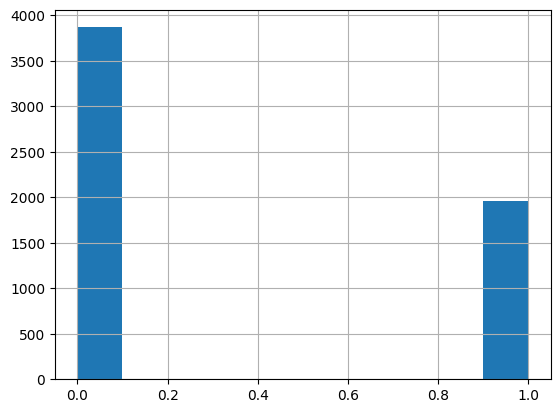

In [7]:
low_mass_satellite_df['quenching_vector'].hist()

In [8]:
galaxy_class_counts = low_mass_satellite_df.groupby("subID")["quenching_vector"].nunique()

# count galaxies with only one class vs. two classes
num_single_class_galaxies = (galaxy_class_counts == 1).sum()
num_two_class_galaxies = (galaxy_class_counts > 1).sum()

print(f"Number of galaxies with only one class: {num_single_class_galaxies}")
print(f"Number of galaxies with two classes: {num_two_class_galaxies}")

Number of galaxies with only one class: 525
Number of galaxies with two classes: 300


In [9]:
import numpy as np

# galaxy_class_counts = low_mass_satellite_df.groupby("subID")["quenching_vector"].nunique()


# # single-class and multi-class galaxies
# single_class_galaxies = galaxy_class_counts[galaxy_class_counts == 1].index
# multi_class_galaxies = galaxy_class_counts[galaxy_class_counts > 1].index

# # keep a random fraction
# fraction_to_keep = 1 
# kept_single_class_galaxies = np.random.choice(single_class_galaxies, 
#                                               size=int(len(single_class_galaxies) * fraction_to_keep), 
#                                               replace=False)

# filtered_galaxies = np.concatenate([kept_single_class_galaxies, multi_class_galaxies])

# filtered_df = low_mass_satellite_df[low_mass_satellite_df["subID"].isin(filtered_galaxies)]

# print(f"Original dataset size: {low_mass_satellite_df.shape}")
# print(f"Filtered dataset size: {filtered_df.shape}")


In [10]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import RobustScaler

# 'BHMass', 'BHCum_QM', 'Mhalo', and 'overdens'are the features wer are testing
low_mass_satellite_df = low_mass_satellite_df.drop(columns=["class", "BH_cumQM", "BH_cumRM", "global_SFRs", "avg_SFR","avg_gas_mass", "gas_mass", "Bfld", "veldisp", "BH_AGN", "bulge"])
low_mass_satellite_df.duplicated()

# X = low_mass_satellite_df.drop(['quenching_vector'], axis=1)
# y = low_mass_satellite_df['quenching_vector']

439      False
440      False
441      False
442      False
443      False
         ...  
54860    False
54861    False
54862    False
54863    False
54864    False
Length: 5831, dtype: bool

In [11]:
low_mass_satellite_df

,subID,bin_radii,avg_s_mass,quenching_vector,s_mass,BHMass,Mhalo,overdens,GrNr
439,37.0,0.174505,8.905776,0,1.336990,0.003621,38878.035156,202.795135,0
440,37.0,0.523516,8.636583,0,1.336990,0.003621,38878.035156,202.795135,0
441,37.0,0.872526,8.421218,0,1.336990,0.003621,38878.035156,202.795135,0
442,37.0,1.221537,8.243556,0,1.336990,0.003621,38878.035156,202.795135,0
443,37.0,1.570547,8.094305,0,1.336990,0.003621,38878.035156,202.795135,0
...,...,...,...,...,...,...,...,...,...
54860,593573.0,0.461125,7.915781,1,0.146896,0.000124,21.333946,3.807714,5991
54861,593573.0,0.768541,7.496673,0,0.146896,0.000124,21.333946,3.807714,5991
54862,593573.0,1.075957,7.168706,0,0.146896,0.000124,21.333946,3.807714,5991
54863,593573.0,1.383374,6.925375,0,0.146896,0.000124,21.333946,3.807714,5991


Seed 0: Train samples: 2845, Test samples: 2986
Train class distribution: quenching_vector
0    1923
1     922
Name: count, dtype: int64
Test class distribution: quenching_vector
0    1944
1    1042
Name: count, dtype: int64

Seed 0:
  Train quenched fraction: 0.324
  Test quenched fraction: 0.349
  Train unique galaxies: 229
  Train Mhalo range: 21.7 - 38878.0
  Test Mhalo range: 21.3 - 33181.0
  Train quenched galaxies: 242
  Test quenched galaxies: 268
Fitting 5 folds for each of 10 candidates, totalling 50 fits


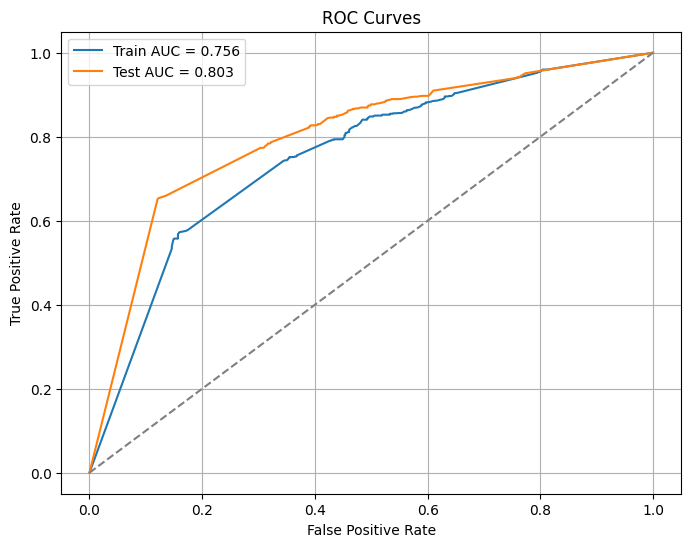

{'n_estimators': 600, 'min_samples_split': 150, 'min_samples_leaf': 500, 'max_features': None, 'max_depth': 50, 'class_weight': 'balanced', 'bootstrap': True}
Gap (Train - Test AUC): -0.0468
Overfitting ratio (Train/Test AUC): 0.9417


Seed 1: Train samples: 2914, Test samples: 2917
Train class distribution: quenching_vector
0    1919
1     995
Name: count, dtype: int64
Test class distribution: quenching_vector
0    1948
1     969
Name: count, dtype: int64

Seed 1:
  Train quenched fraction: 0.341
  Test quenched fraction: 0.332
  Train unique galaxies: 229
  Train Mhalo range: 21.7 - 33181.0
  Test Mhalo range: 21.3 - 38878.0
  Train quenched galaxies: 255
  Test quenched galaxies: 255
Fitting 5 folds for each of 10 candidates, totalling 50 fits


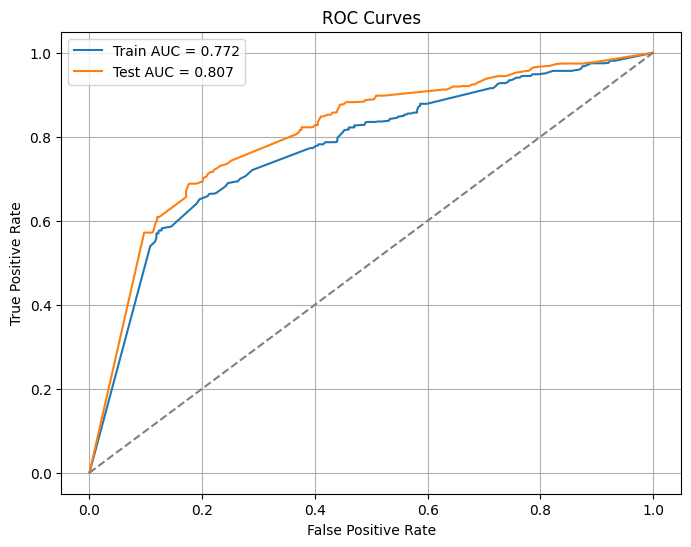

{'n_estimators': 600, 'min_samples_split': 125, 'min_samples_leaf': 500, 'max_features': None, 'max_depth': 45, 'class_weight': 'balanced', 'bootstrap': True}
Gap (Train - Test AUC): -0.0353
Overfitting ratio (Train/Test AUC): 0.9563


Seed 2: Train samples: 3061, Test samples: 2770
Train class distribution: quenching_vector
0    2000
1    1061
Name: count, dtype: int64
Test class distribution: quenching_vector
0    1867
1     903
Name: count, dtype: int64

Seed 2:
  Train quenched fraction: 0.347
  Test quenched fraction: 0.326
  Train unique galaxies: 229
  Train Mhalo range: 21.3 - 38878.0
  Test Mhalo range: 21.7 - 26720.1
  Train quenched galaxies: 266
  Test quenched galaxies: 244
Fitting 5 folds for each of 10 candidates, totalling 50 fits


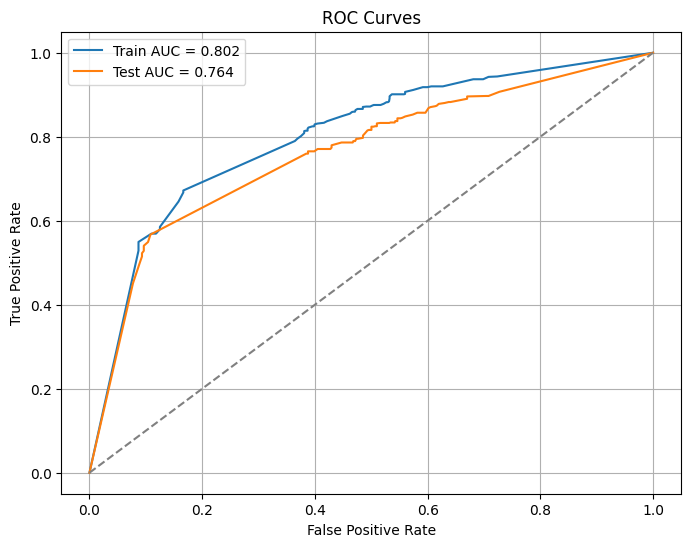

{'n_estimators': 500, 'min_samples_split': 125, 'min_samples_leaf': 500, 'max_features': None, 'max_depth': 45, 'class_weight': 'balanced', 'bootstrap': True}
Gap (Train - Test AUC): 0.0379
Overfitting ratio (Train/Test AUC): 1.0496


Seed 3: Train samples: 3048, Test samples: 2783
Train class distribution: quenching_vector
0    2025
1    1023
Name: count, dtype: int64
Test class distribution: quenching_vector
0    1842
1     941
Name: count, dtype: int64

Seed 3:
  Train quenched fraction: 0.336
  Test quenched fraction: 0.338
  Train unique galaxies: 229
  Train Mhalo range: 21.7 - 38878.0
  Test Mhalo range: 21.3 - 25922.5
  Train quenched galaxies: 265
  Test quenched galaxies: 245
Fitting 5 folds for each of 10 candidates, totalling 50 fits


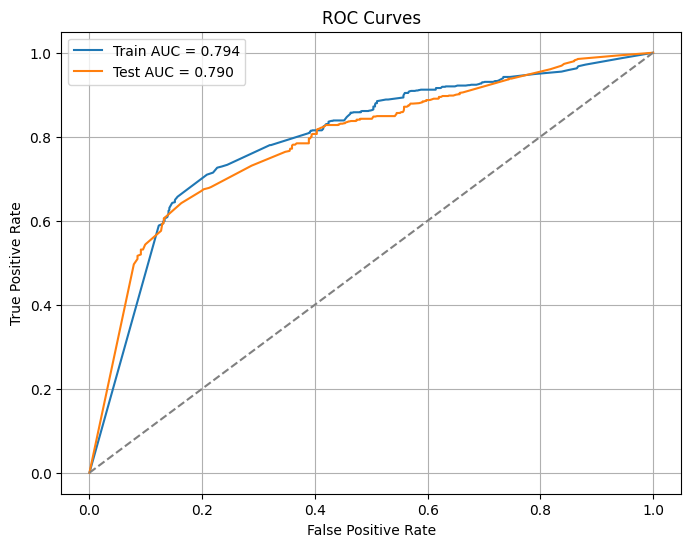

{'n_estimators': 700, 'min_samples_split': 125, 'min_samples_leaf': 500, 'max_features': None, 'max_depth': 45, 'class_weight': 'balanced', 'bootstrap': True}
Gap (Train - Test AUC): 0.0043
Overfitting ratio (Train/Test AUC): 1.0055
Seed 4: Train samples: 3134, Test samples: 2697
Train class distribution: quenching_vector
0    2064
1    1070
Name: count, dtype: int64
Test class distribution: quenching_vector
0    1803
1     894
Name: count, dtype: int64

Seed 4:
  Train quenched fraction: 0.341
  Test quenched fraction: 0.331
  Train unique galaxies: 229
  Train Mhalo range: 21.7 - 38878.0
  Test Mhalo range: 21.3 - 33181.0
  Train quenched galaxies: 280
  Test quenched galaxies: 230
Fitting 5 folds for each of 10 candidates, totalling 50 fits


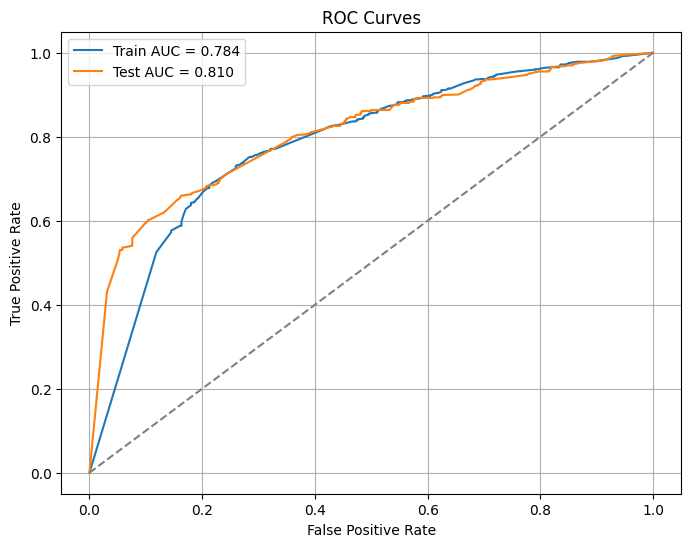

{'n_estimators': 700, 'min_samples_split': 125, 'min_samples_leaf': 500, 'max_features': None, 'max_depth': 40, 'class_weight': 'balanced', 'bootstrap': True}
Gap (Train - Test AUC): -0.0254
Overfitting ratio (Train/Test AUC): 0.9687


Seed 5: Train samples: 2657, Test samples: 3174
Train class distribution: quenching_vector
0    1846
1     811
Name: count, dtype: int64
Test class distribution: quenching_vector
0    2021
1    1153
Name: count, dtype: int64

Seed 5:
  Train quenched fraction: 0.305
  Test quenched fraction: 0.363
  Train unique galaxies: 229
  Train Mhalo range: 21.7 - 25922.5
  Test Mhalo range: 21.3 - 38878.0
  Train quenched galaxies: 221
  Test quenched galaxies: 289
Fitting 5 folds for each of 10 candidates, totalling 50 fits


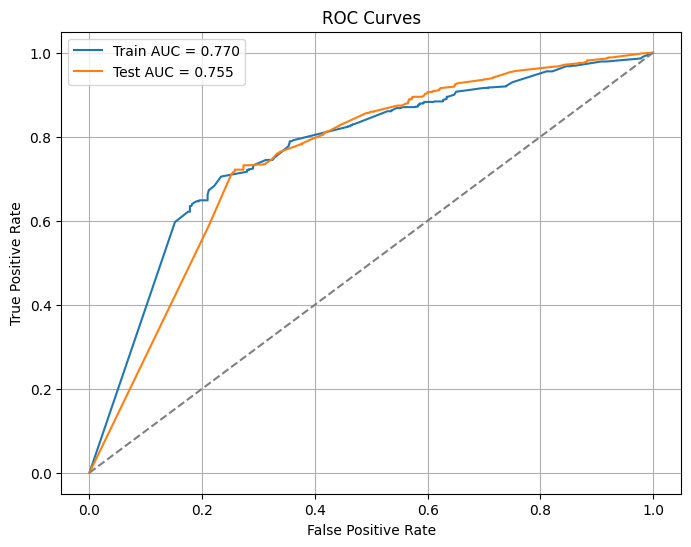

{'n_estimators': 700, 'min_samples_split': 150, 'min_samples_leaf': 550, 'max_features': None, 'max_depth': 40, 'class_weight': 'balanced', 'bootstrap': True}
Gap (Train - Test AUC): 0.0152
Overfitting ratio (Train/Test AUC): 1.0201
Seed 6: Train samples: 2824, Test samples: 3007
Train class distribution: quenching_vector
0    2002
1     822
Name: count, dtype: int64
Test class distribution: quenching_vector
0    1865
1    1142
Name: count, dtype: int64

Seed 6:
  Train quenched fraction: 0.291
  Test quenched fraction: 0.380
  Train unique galaxies: 229
  Train Mhalo range: 21.3 - 33181.0
  Test Mhalo range: 27.0 - 38878.0
  Train quenched galaxies: 226
  Test quenched galaxies: 284
Fitting 5 folds for each of 10 candidates, totalling 50 fits


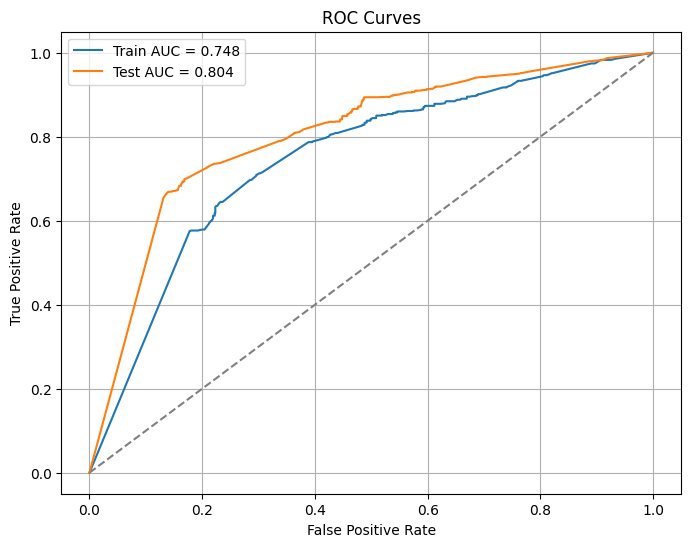

{'n_estimators': 700, 'min_samples_split': 100, 'min_samples_leaf': 550, 'max_features': None, 'max_depth': 45, 'class_weight': 'balanced', 'bootstrap': True}
Gap (Train - Test AUC): -0.0565
Overfitting ratio (Train/Test AUC): 0.9298


Seed 7: Train samples: 3098, Test samples: 2733
Train class distribution: quenching_vector
0    1902
1    1196
Name: count, dtype: int64
Test class distribution: quenching_vector
0    1965
1     768
Name: count, dtype: int64

Seed 7:
  Train quenched fraction: 0.386
  Test quenched fraction: 0.281
  Train unique galaxies: 229
  Train Mhalo range: 21.3 - 38878.0
  Test Mhalo range: 21.7 - 26720.1
  Train quenched galaxies: 292
  Test quenched galaxies: 218
Fitting 5 folds for each of 10 candidates, totalling 50 fits


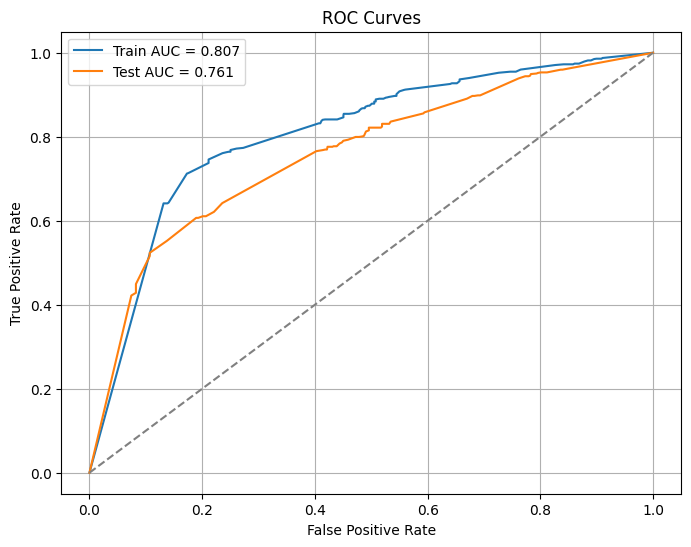

{'n_estimators': 700, 'min_samples_split': 150, 'min_samples_leaf': 525, 'max_features': None, 'max_depth': 40, 'class_weight': 'balanced', 'bootstrap': True}
Gap (Train - Test AUC): 0.0467
Overfitting ratio (Train/Test AUC): 1.0614


Seed 8: Train samples: 2926, Test samples: 2905
Train class distribution: quenching_vector
0    1924
1    1002
Name: count, dtype: int64
Test class distribution: quenching_vector
0    1943
1     962
Name: count, dtype: int64

Seed 8:
  Train quenched fraction: 0.342
  Test quenched fraction: 0.331
  Train unique galaxies: 229
  Train Mhalo range: 27.0 - 26720.1
  Test Mhalo range: 21.3 - 38878.0
  Train quenched galaxies: 257
  Test quenched galaxies: 253
Fitting 5 folds for each of 10 candidates, totalling 50 fits


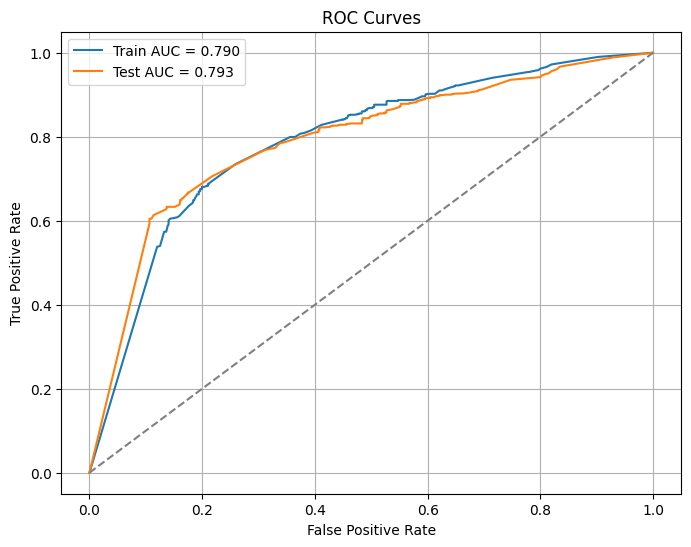

{'n_estimators': 700, 'min_samples_split': 100, 'min_samples_leaf': 500, 'max_features': None, 'max_depth': 45, 'class_weight': 'balanced', 'bootstrap': True}
Gap (Train - Test AUC): -0.0027
Overfitting ratio (Train/Test AUC): 0.9965
Seed 9: Train samples: 3090, Test samples: 2741
Train class distribution: quenching_vector
0    1994
1    1096
Name: count, dtype: int64
Test class distribution: quenching_vector
0    1873
1     868
Name: count, dtype: int64

Seed 9:
  Train quenched fraction: 0.355
  Test quenched fraction: 0.317
  Train unique galaxies: 229
  Train Mhalo range: 36.4 - 38878.0
  Test Mhalo range: 21.3 - 26720.1
  Train quenched galaxies: 274
  Test quenched galaxies: 236
Fitting 5 folds for each of 10 candidates, totalling 50 fits


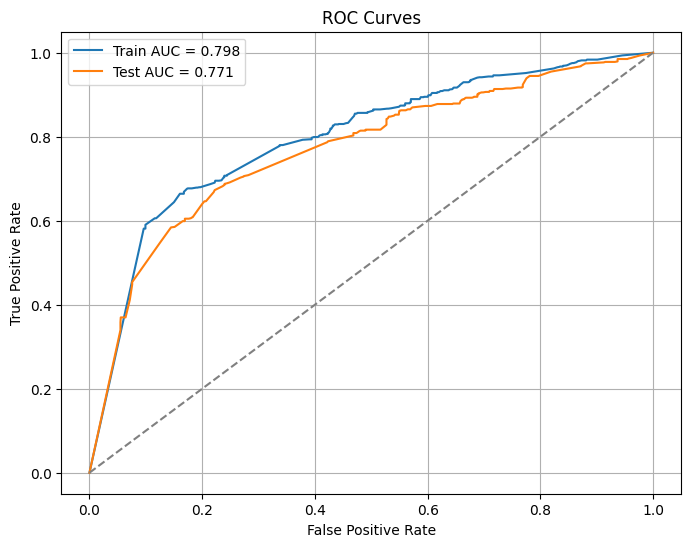

{'n_estimators': 700, 'min_samples_split': 125, 'min_samples_leaf': 500, 'max_features': None, 'max_depth': 45, 'class_weight': 'balanced', 'bootstrap': True}
Gap (Train - Test AUC): 0.0274
Overfitting ratio (Train/Test AUC): 1.0356

Average AUC over 10 runs:
Train AUC: Mean = 0.7822, Std = 0.0191
Test AUC:  Mean = 0.7857, Std = 0.0200
Train F1: Mean = 0.6360, Std = 0.0331
Test F1:  Mean = 0.6223, Std = 0.0643

Gap stats: Mean = -0.0035, Std = 0.0343, Min = -0.0565, Max = 0.0467
Overfitting ratio stats: Mean = 0.9965, Std = 0.0436


In [12]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedGroupKFold


# splitting galaxies into test/train based on subID
unique_halos = np.unique(low_mass_satellite_df['GrNr'])

train_aucs = []
test_aucs = []
feature_importances_list = []
feature_names = None
train_f1s = []
test_f1s = []


for seed in range(10):
    train_galaxies, test_galaxies = train_test_split(unique_halos, test_size=0.5, random_state=seed)

    train_data = low_mass_satellite_df[low_mass_satellite_df['GrNr'].isin(train_galaxies)]
    test_data = low_mass_satellite_df[low_mass_satellite_df['GrNr'].isin(test_galaxies)]

    X_train, y_train = train_data.drop(columns=['quenching_vector', 'subID','GrNr']), train_data['quenching_vector']
    X_test, y_test = test_data.drop(columns=['quenching_vector', 'subID','GrNr']), test_data['quenching_vector']

    print(f"Seed {seed}: Train samples: {len(X_train)}, Test samples: {len(X_test)}")
    print(f"Train class distribution: {y_train.value_counts()}")
    print(f"Test class distribution: {y_test.value_counts()}")

    # Add this after your train/test split, before fitting
    print(f"\nSeed {seed}:")
    print(f"  Train quenched fraction: {y_train.mean():.3f}")
    print(f"  Test quenched fraction: {y_test.mean():.3f}")

    # Check how many unique Mhalo values are in train vs test
    print(f"  Train unique galaxies: {len(train_galaxies)}")
    print(f"  Train Mhalo range: {X_train['Mhalo'].min():.1f} - {X_train['Mhalo'].max():.1f}")
    print(f"  Test Mhalo range: {X_test['Mhalo'].min():.1f} - {X_test['Mhalo'].max():.1f}")

    # What fraction of quenched bins come from single-class quenched galaxies
    train_quenched_ids = train_data[train_data['quenching_vector']==1]['subID'].unique()
    test_quenched_ids = test_data[test_data['quenching_vector']==1]['subID'].unique()
    print(f"  Train quenched galaxies: {len(train_quenched_ids)}")
    print(f"  Test quenched galaxies: {len(test_quenched_ids)}")

    if feature_names is None:
        feature_names = X_train.columns.tolist()
    # scaling
    scaler = RobustScaler()
    X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=X_train.columns)
    X_test_scaled = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns)

    param_grid = {
    'n_estimators': [500, 600, 700],
    'max_depth': [40, 45, 50],
    'min_samples_split': [100, 125, 150],
    'min_samples_leaf': [500, 525, 550],
    'max_features': [None],
    'bootstrap': [True],
    'class_weight': ['balanced']
    }
    rf = RandomForestClassifier(random_state=seed)
    groups_train = train_data['GrNr']
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)

    random_search = RandomizedSearchCV(
    estimator=rf, 
    param_distributions=param_grid, 
    n_iter=10,
    cv=cv, 
    scoring='roc_auc',
    n_jobs=-1,
    random_state=seed,
    verbose=2)

    random_search.fit(X_train_scaled, y_train, groups=groups_train)

    best_rf = random_search.best_estimator_

    y_train_prob = best_rf.predict_proba(X_train_scaled)[:, 1]
    y_test_prob = best_rf.predict_proba(X_test_scaled)[:, 1]

    fpr_train, tpr_train, _ = roc_curve(y_train, y_train_prob)
    fpr_test, tpr_test, _ = roc_curve(y_test, y_test_prob)

    # ROC curves
    plt.figure(figsize=(8,6))
    plt.plot(fpr_train, tpr_train, label=f'Train AUC = {roc_auc_score(y_train, y_train_prob):.3f}')
    plt.plot(fpr_test, tpr_test, label=f'Test AUC = {roc_auc_score(y_test, y_test_prob):.3f}')
    plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title('ROC Curves')
    plt.legend()
    plt.grid(True)
    plt.show()
    print(random_search.best_params_)

    
    # aucs and feature importance
    train_auc = roc_auc_score(y_train, y_train_prob)
    test_auc = roc_auc_score(y_test, y_test_prob)
    gap = train_auc - test_auc
    print(f"Gap (Train - Test AUC): {gap:.4f}")
    print(f"Overfitting ratio (Train/Test AUC): {train_auc / test_auc:.4f}")
    feature_importances_list.append(best_rf.feature_importances_)
    
    train_aucs.append(train_auc)
    test_aucs.append(test_auc)


    y_train_pred = best_rf.predict(X_train_scaled)
    y_test_pred = best_rf.predict(X_test_scaled)

    # f1 scores
    train_f1 = f1_score(y_train, y_train_pred)
    test_f1 = f1_score(y_test, y_test_pred)

    train_f1s.append(train_f1)
    test_f1s.append(test_f1)
    
print("\nAverage AUC over 10 runs:")
print(f"Train AUC: Mean = {np.mean(train_aucs):.4f}, Std = {np.std(train_aucs):.4f}")
print(f"Test AUC:  Mean = {np.mean(test_aucs):.4f}, Std = {np.std(test_aucs):.4f}")
print(f"Train F1: Mean = {np.mean(train_f1s):.4f}, Std = {np.std(train_f1s):.4f}")
print(f"Test F1:  Mean = {np.mean(test_f1s):.4f}, Std = {np.std(test_f1s):.4f}")
gaps = [train - test for train, test in zip(train_aucs, test_aucs)]
overfit_ratios = [train / test for train, test in zip(train_aucs, test_aucs)]
print(f"\nGap stats: Mean = {np.mean(gaps):.4f}, Std = {np.std(gaps):.4f}, Min = {np.min(gaps):.4f}, Max = {np.max(gaps):.4f}")
print(f"Overfitting ratio stats: Mean = {np.mean(overfit_ratios):.4f}, Std = {np.std(overfit_ratios):.4f}")


=== Average Feature Importances ===
      Feature  Mean Importance   Std Dev
4       Mhalo         0.903899  0.031138
3      BHMass         0.066179  0.040615
2      s_mass         0.027349  0.018905
5    overdens         0.001865  0.003463
1  avg_s_mass         0.000690  0.000882
0   bin_radii         0.000018  0.000038


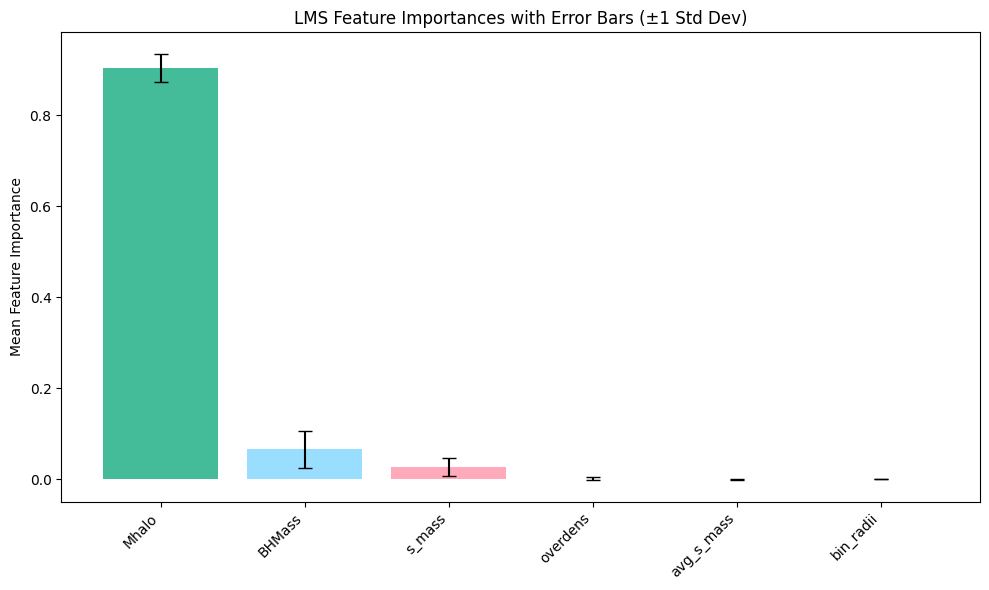

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
feature_colors = {
    'bin_radii': '#77AADD',
    'avg_s_mass': '#EE8866',
    's_mass': '#FFAABB',
    'BHMass': '#99DDFF',
    'Mhalo': '#44BB99',
    'overdens': '#BBCC33',
    'bulge': '#AAAA00',
    'BH_AGN': '#DDDDDD',
}

# importances + stds across 10 runs
importances_array = np.array(feature_importances_list)
importance_means = np.mean(importances_array, axis=0)
importance_stds = np.std(importances_array, axis=0)

importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Mean Importance': importance_means,
    'Std Dev': importance_stds
}).sort_values(by='Mean Importance', ascending=False)

print("\n=== Average Feature Importances ===")
print(importance_df)

colors = [feature_colors[feat] for feat in importance_df['Feature']]
# Plot
plt.figure(figsize=(10, 6))
plt.bar(importance_df['Feature'], importance_df['Mean Importance'], yerr=importance_df['Std Dev'], capsize=5, color=colors)
plt.xticks(rotation=45, ha='right')
plt.ylabel("Mean Feature Importance")
plt.title("LMS Feature Importances with Error Bars (±1 Std Dev)")
plt.tight_layout()
plt.show()

In [14]:
low_mass_satellite_df.corr()

,subID,bin_radii,avg_s_mass,quenching_vector,s_mass,BHMass,Mhalo,overdens,GrNr
subID,1.000000,0.012483,-0.147451,-0.439784,-0.119578,-0.018875,-0.806539,-0.187313,0.740342
bin_radii,0.012483,1.000000,-0.763786,-0.014536,0.008626,0.006630,-0.009713,-0.002019,0.006344
avg_s_mass,-0.147451,-0.763786,1.000000,-0.016354,0.400759,0.370520,0.095505,0.053804,-0.159357
quenching_vector,-0.439784,-0.014536,-0.016354,1.000000,-0.149585,-0.208122,0.428620,0.078651,-0.203264
s_mass,-0.119578,0.008626,0.400759,-0.149585,1.000000,0.872315,0.042330,0.074692,-0.205946
BHMass,-0.018875,0.006630,0.370520,-0.208122,0.872315,1.000000,-0.039114,0.019820,-0.140233
Mhalo,-0.806539,-0.009713,0.095505,0.428620,0.042330,-0.039114,1.000000,0.111680,-0.373665
overdens,-0.187313,-0.002019,0.053804,0.078651,0.074692,0.019820,0.111680,1.000000,-0.137245
GrNr,0.740342,0.006344,-0.159357,-0.203264,-0.205946,-0.140233,-0.373665,-0.137245,1.000000


In [15]:
train_mean = round(np.mean(train_aucs), 2)
test_mean = round(np.mean(test_aucs), 2)
print(train_mean)
df = pd.DataFrame({
    'Train AUC': [train_mean],
    'Test AUC': [test_mean]
})

print(df)
import os
# Define your directory and file name
directory = os.path.join(OUT_ROOT, 'rf_classification_outputs')
filename = 'lms_rf_quenching_auc_halosplit.csv'
filepath = os.path.join(directory, filename)

# Create the directory if it doesn't exist
os.makedirs(directory, exist_ok=True)

# Save the DataFrame
df.to_csv(filepath, index=False)

print(f'DataFrame saved to {filepath}')

0.78
   Train AUC  Test AUC
0       0.78      0.79
DataFrame saved to ..\..\outputs\thresh_m2.0\rf_classification_outputs\lms_rf_quenching_auc_halosplit.csv


In [16]:
import os
# Define your directory and file name
directory = os.path.join(OUT_ROOT, 'rf_classification_outputs')
filename = 'lms_rf_quenching_halosplit.csv'
filepath = os.path.join(directory, filename)

# Create the directory if it doesn't exist
os.makedirs(directory, exist_ok=True)

# Save the DataFrame
importance_df.to_csv(filepath, index=False)

print(f'DataFrame saved to {filepath}')

DataFrame saved to ..\..\outputs\thresh_m2.0\rf_classification_outputs\lms_rf_quenching_halosplit.csv
